# Air Quality Analysis and PM2.5 Prediction in Ratnanagar, Nepal

**Author:** Bandana Dhakal

**Study Area:** Ratnanagar, Chitwan, Nepal

**Study Period:** January–December 2025

## Project Objectives

1. Analyze historical PM2.5 and PM10 concentrations.
2. Examine monthly and seasonal air-quality patterns.
3. Investigate relationships between pollutants.
4. Analyze Air Quality Index (AQI) variations.
5. Develop machine learning models to predict PM2.5.
6. Evaluate prediction accuracy.

In [1]:
# Import libraries for data analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests

print("All libraries imported successfully!")
print("Ratnanagar Air Quality Project is ready!")

All libraries imported successfully!
Ratnanagar Air Quality Project is ready!


In [2]:
# STEP 3: Collect Air Quality Data for Ratnanagar

import requests
import pandas as pd

# Location: Ratnanagar, Chitwan, Nepal
latitude = 27.61937
longitude = 84.52011

# Historical air quality API
url = "https://air-quality-api.open-meteo.com/v1/air-quality"

# Parameters
params = {
    "latitude": latitude,
    "longitude": longitude,
    "start_date": "2025-01-01",
    "end_date": "2025-12-31",
    "hourly": "pm2_5,pm10,us_aqi,nitrogen_dioxide,ozone",
    "timezone": "Asia/Kathmandu"
}

# Request data
response = requests.get(url, params=params, timeout=60)

# Check whether the request succeeded
print("HTTP Status:", response.status_code)

if response.status_code == 200:

    data = response.json()

    # Convert to Pandas DataFrame
    df = pd.DataFrame(data["hourly"])

    # Convert time to datetime
    df["time"] = pd.to_datetime(df["time"])

    # Display first five rows
    print(df.head())

    # Display total number of records
    print("Total Records:", len(df))

    # Save dataset
    df.to_csv("Ratnanagar_Air_Quality_2025.csv", index=False)

    print("Dataset saved successfully!")

else:
    print("API Error:", response.text[:1000])

HTTP Status: 200
                 time  pm2_5  pm10  us_aqi  nitrogen_dioxide  ozone
0 2025-01-01 00:00:00   78.0  78.0     157              15.4   83.0
1 2025-01-01 01:00:00   82.9  82.9     157              16.9   76.0
2 2025-01-01 02:00:00   87.3  87.3     157              17.7   71.0
3 2025-01-01 03:00:00   91.0  91.0     156              17.3   69.0
4 2025-01-01 04:00:00   92.7  92.7     156              16.2   68.0
Total Records: 8760
Dataset saved successfully!


In [3]:
# STEP 4: Understanding the Dataset

print("DATASET INFORMATION")
print("-------------------")

df.info()

print("\nDATASET DIMENSIONS")
print("-------------------")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nCOLUMN NAMES")
print("-------------------")
print(df.columns.tolist())

print("\nMISSING VALUES")
print("-------------------")
print(df.isnull().sum())

print("\nDUPLICATE TIMESTAMPS")
print("-------------------")
print(df["time"].duplicated().sum())

print("\nSTATISTICAL SUMMARY")
print("-------------------")
print(df.describe())

DATASET INFORMATION
-------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   time              8760 non-null   datetime64[ns]
 1   pm2_5             8760 non-null   float64       
 2   pm10              8760 non-null   float64       
 3   us_aqi            8760 non-null   int64         
 4   nitrogen_dioxide  8760 non-null   float64       
 5   ozone             8760 non-null   float64       
dtypes: datetime64[ns](1), float64(4), int64(1)
memory usage: 410.8 KB

DATASET DIMENSIONS
-------------------
Rows: 8760
Columns: 6

COLUMN NAMES
-------------------
['time', 'pm2_5', 'pm10', 'us_aqi', 'nitrogen_dioxide', 'ozone']

MISSING VALUES
-------------------
time                0
pm2_5               0
pm10                0
us_aqi              0
nitrogen_dioxide    0
ozone               0
dtype: int64

DUPLICAT

In [4]:
# STEP 5: Data Cleaning and Preparation

# Create a copy of the original dataset
df_clean = df.copy()

# Convert time column to datetime
df_clean["time"] = pd.to_datetime(df_clean["time"])

# Sort observations by time
df_clean = df_clean.sort_values("time")

# Remove duplicate timestamps
df_clean = df_clean.drop_duplicates(subset=["time"])

# Check missing values
print("Missing values before cleaning:")
print(df_clean.isnull().sum())

# Create additional time-related columns
df_clean["year"] = df_clean["time"].dt.year
df_clean["month"] = df_clean["time"].dt.month
df_clean["day"] = df_clean["time"].dt.day
df_clean["hour"] = df_clean["time"].dt.hour

# Check final dataset
print("\nCleaned Dataset:")
print(df_clean.head())

print("\nTotal Rows:", len(df_clean))

# Save cleaned dataset
df_clean.to_csv(
    "Ratnanagar_Air_Quality_Cleaned_2025.csv",
    index=False
)

print("\nCleaned dataset saved successfully!")

Missing values before cleaning:
time                0
pm2_5               0
pm10                0
us_aqi              0
nitrogen_dioxide    0
ozone               0
dtype: int64

Cleaned Dataset:
                 time  pm2_5  pm10  us_aqi  nitrogen_dioxide  ozone  year  \
0 2025-01-01 00:00:00   78.0  78.0     157              15.4   83.0  2025   
1 2025-01-01 01:00:00   82.9  82.9     157              16.9   76.0  2025   
2 2025-01-01 02:00:00   87.3  87.3     157              17.7   71.0  2025   
3 2025-01-01 03:00:00   91.0  91.0     156              17.3   69.0  2025   
4 2025-01-01 04:00:00   92.7  92.7     156              16.2   68.0  2025   

   month  day  hour  
0      1    1     0  
1      1    1     1  
2      1    1     2  
3      1    1     3  
4      1    1     4  

Total Rows: 8760

Cleaned dataset saved successfully!


## 6. Exploratory Data Analysis (EDA)

### 6.1 Monthly Variation in PM2.5 Concentration

This analysis investigates monthly variations in estimated
PM2.5 concentrations in Ratnanagar, Chitwan, Nepal,
during January–December 2025.

Monthly averages are calculated from hourly modelled
PM2.5 concentrations to identify seasonal pollution patterns.

Monthly Average PM2.5:
month
1     85.48
2     74.26
3     50.93
4     51.77
5     40.50
6     42.53
7     34.13
8     29.19
9     28.09
10    36.28
11    46.86
12    66.65
Name: pm2_5, dtype: float64


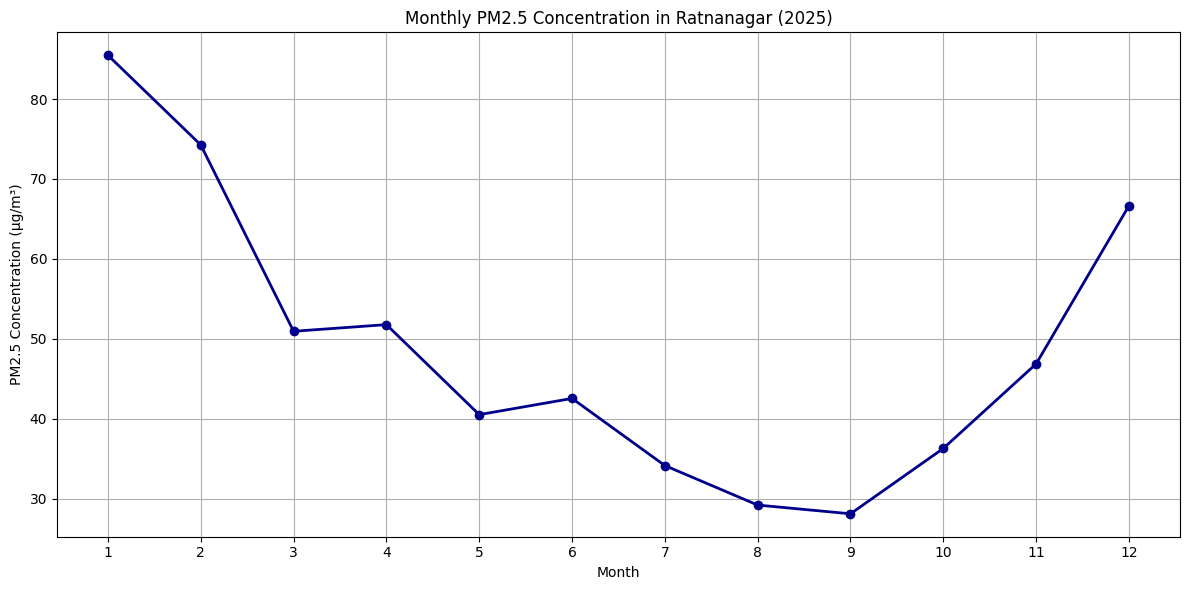

In [5]:
# Calculate monthly average PM2.5

monthly_pm25 = df_clean.groupby("month")["pm2_5"].mean()

print("Monthly Average PM2.5:")
print(monthly_pm25.round(2))

# Create graph
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_pm25.index,
    monthly_pm25.values,
    marker="o",
    color="darkblue",
    linewidth=2
)

plt.title("Monthly PM2.5 Concentration in Ratnanagar (2025)")
plt.xlabel("Month")
plt.ylabel("PM2.5 Concentration (µg/m³)")

plt.xticks(range(1, 13))
plt.grid(True)

plt.tight_layout()
plt.savefig("Ratnanagar_Monthly_PM25_2025.png", dpi=300)
plt.show()

### 6.2 Comparison of Monthly PM2.5 and PM10 Concentrations

This analysis compares monthly average PM2.5 and PM10
concentrations in Ratnanagar during 2025.

The objective is to investigate seasonal variations`
and differences between fine and inhalable particulate matter.

Monthly PM2.5 and PM10 Concentrations:
       pm2_5   pm10
month              
1      85.48  87.19
2      74.26  86.88
3      50.93  76.95
4      51.77  73.88
5      40.50  65.62
6      42.53  61.39
7      34.13  36.09
8      29.19  31.12
9      28.09  28.77
10     36.28  38.45
11     46.86  49.81
12     66.65  68.39


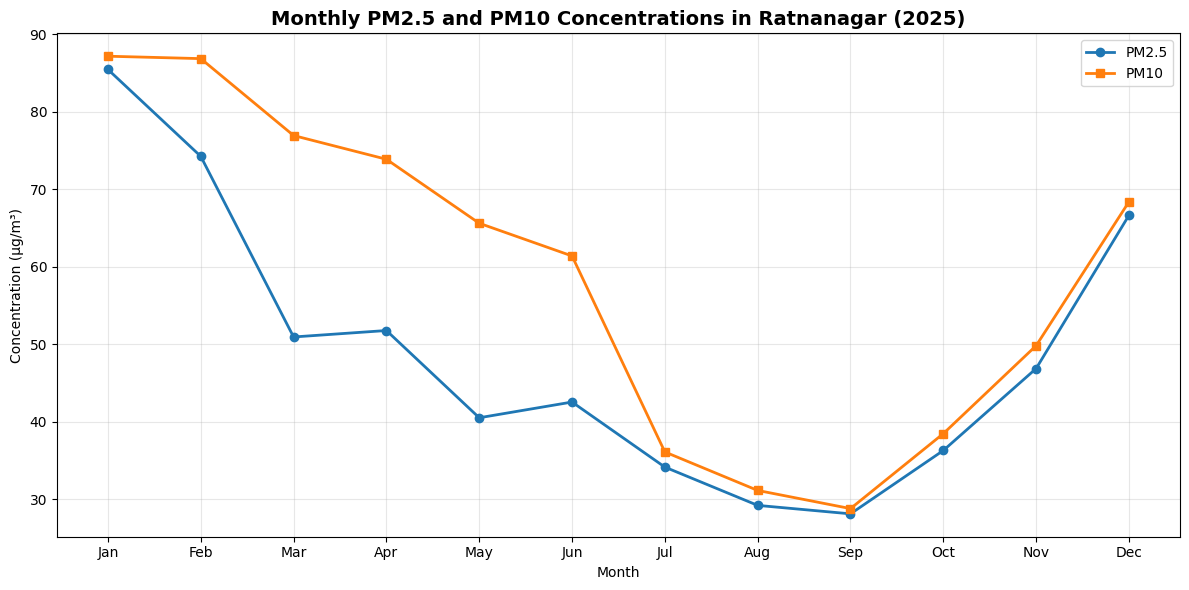

In [6]:
# STEP 7: Compare PM2.5 and PM10

# Calculate monthly averages
monthly_pollution = df_clean.groupby("month")[["pm2_5", "pm10"]].mean()

print("Monthly PM2.5 and PM10 Concentrations:")
print(monthly_pollution.round(2))

# Create graph
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_pollution.index,
    monthly_pollution["pm2_5"],
    marker="o",
    linewidth=2,
    label="PM2.5"
)

plt.plot(
    monthly_pollution.index,
    monthly_pollution["pm10"],
    marker="s",
    linewidth=2,
    label="PM10"
)

plt.title(
    "Monthly PM2.5 and PM10 Concentrations in Ratnanagar (2025)",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Month")
plt.ylabel("Concentration (µg/m³)")

plt.xticks(
    range(1, 13),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save graph
plt.savefig("Ratnanagar_PM25_PM10_Comparison_2025.png", dpi=300)

plt.show()

### 6.3 Air Quality Index (AQI) Classification

This analysis classifies hourly US AQI estimates into
standard air-quality categories.

The objective is to examine the frequency and percentage
of hours falling within each AQI category in Ratnanagar
during 2025.

AQI Classification Summary:
                                Hours  Percentage
AQI_Category                                     
Good                                0        0.00
Moderate                         3028       34.57
Unhealthy for Sensitive Groups   2832       32.33
Unhealthy                        2900       33.11
Very Unhealthy                      0        0.00
Hazardous                           0        0.00


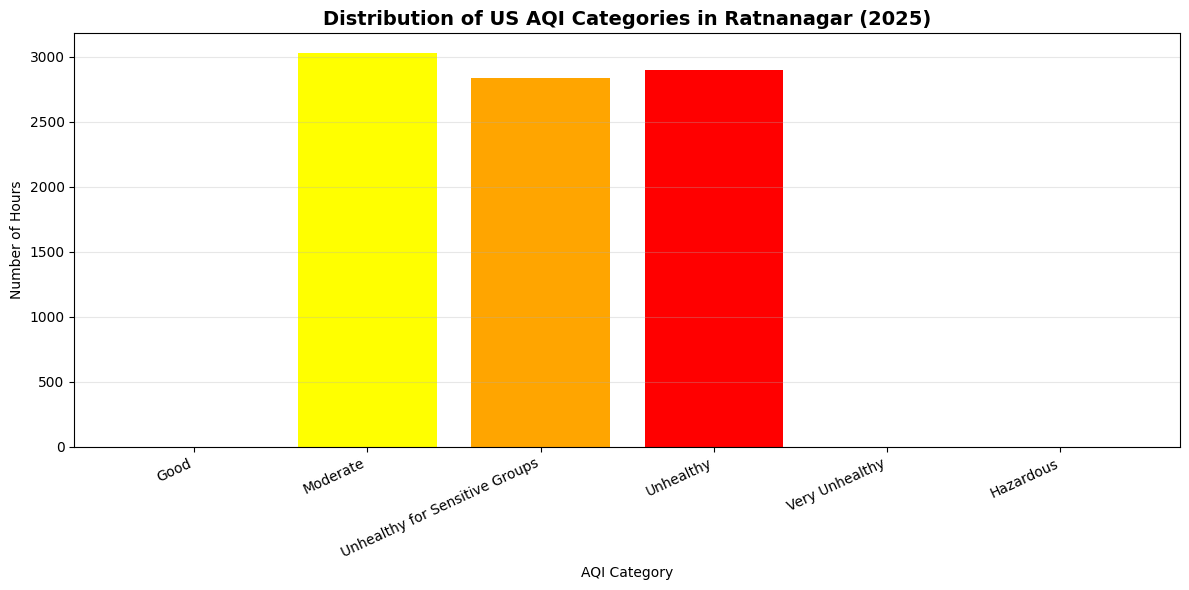

In [7]:
# STEP 8: AQI Classification

import pandas as pd
import matplotlib.pyplot as plt

# Define AQI categories
aqi_labels = [
    "Good",
    "Moderate",
    "Unhealthy for Sensitive Groups",
    "Unhealthy",
    "Very Unhealthy",
    "Hazardous"
]

# Classify AQI values
df_clean["AQI_Category"] = pd.cut(
    df_clean["us_aqi"],
    bins=[-float("inf"), 50, 100, 150, 200, 300, float("inf")],
    labels=aqi_labels
)

# Count hours in each category
aqi_counts = df_clean["AQI_Category"].value_counts().reindex(
    aqi_labels, fill_value=0
)

# Calculate percentages
aqi_percentages = (aqi_counts / aqi_counts.sum()) * 100

# Display results
aqi_summary = pd.DataFrame({
    "Hours": aqi_counts,
    "Percentage": aqi_percentages.round(2)
})

print("AQI Classification Summary:")
print(aqi_summary)

# Create bar chart
plt.figure(figsize=(12, 6))

bars = plt.bar(
    aqi_counts.index,
    aqi_counts.values,
    color=["green", "yellow", "orange", "red", "purple", "maroon"]
)

plt.title(
    "Distribution of US AQI Categories in Ratnanagar (2025)",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("AQI Category")
plt.ylabel("Number of Hours")

plt.xticks(rotation=25, ha="right")

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

# Save graph
plt.savefig("Ratnanagar_AQI_Categories_2025.png", dpi=300)

plt.show()

Correlation Matrix:
                  pm2_5  pm10  nitrogen_dioxide  ozone  us_aqi
pm2_5              1.00  0.89              0.59  -0.30    0.70
pm10               0.89  1.00              0.43  -0.11    0.69
nitrogen_dioxide   0.59  0.43              1.00  -0.82    0.09
ozone             -0.30 -0.11             -0.82   1.00    0.23
us_aqi             0.70  0.69              0.09   0.23    1.00


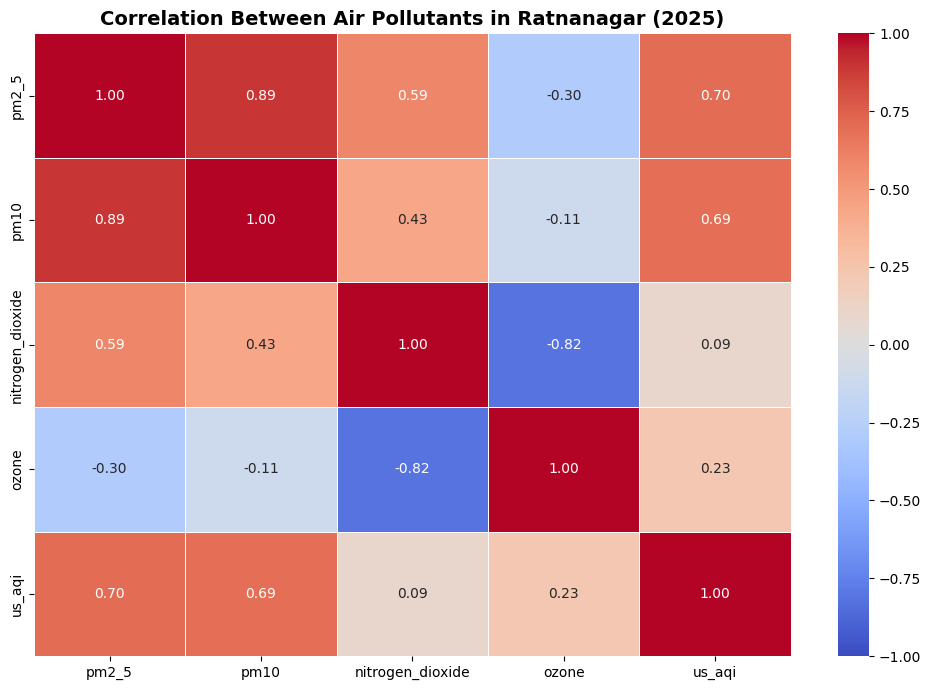

In [8]:
# STEP 9: Correlation Analysis

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Select air quality variables
pollutants = [
    "pm2_5",
    "pm10",
    "nitrogen_dioxide",
    "ozone",
    "us_aqi"
]

# Calculate correlation matrix
correlation_matrix = df_clean[pollutants].corr()

# Display correlation values
print("Correlation Matrix:")
print(correlation_matrix.round(2))

# Create heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title(
    "Correlation Between Air Pollutants in Ratnanagar (2025)",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

# Save graph
plt.savefig(
    "Ratnanagar_Air_Pollution_Correlation_2025.png",
    dpi=300
)

plt.show()

## 7. Machine Learning: Next-Hour PM2.5 Prediction

### 7.1 Feature engineering and chronological evaluation

Predict the PM2.5 concentration at **t + 1 hour** using PM2.5 observed at **t** and earlier hours, plus calendar features known at prediction time. Models use a chronological 80% training / 20% holdout split, rather than a random split, to evaluate future-period performance. Missing values and timestamp gaps are checked before fitting. The source is modelled air-quality data, not ground-station measurements.


In [9]:
# Build next-hour forecasting dataset from the existing cleaned data
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

series = df_clean[['time', 'pm2_5']].copy().sort_values('time').drop_duplicates('time')
series['pm2_5'] = pd.to_numeric(series['pm2_5'], errors='coerce')
series = series.set_index('time').asfreq('h')  # make missing hours explicit
print('Missing hourly PM2.5 values:', int(series['pm2_5'].isna().sum()))

# No interpolation across gaps: keep only fully observed feature/target windows.
ml_df = series.copy()
ml_df['pm25_now'] = ml_df['pm2_5']
for lag in (1, 2, 3, 24):
    ml_df[f'pm25_lag_{lag}'] = ml_df['pm2_5'].shift(lag)
ml_df['pm25_mean_last_6h'] = ml_df['pm2_5'].rolling(6, min_periods=6).mean()
ml_df['pm25_mean_last_24h'] = ml_df['pm2_5'].rolling(24, min_periods=24).mean()
ml_df['hour_sin'] = np.sin(2 * np.pi * ml_df.index.hour / 24)
ml_df['hour_cos'] = np.cos(2 * np.pi * ml_df.index.hour / 24)
ml_df['month_sin'] = np.sin(2 * np.pi * (ml_df.index.month - 1) / 12)
ml_df['month_cos'] = np.cos(2 * np.pi * (ml_df.index.month - 1) / 12)
ml_df['target_next_hour'] = ml_df['pm2_5'].shift(-1)
features = ['pm25_now', 'pm25_lag_1', 'pm25_lag_2', 'pm25_lag_3',
            'pm25_lag_24', 'pm25_mean_last_6h', 'pm25_mean_last_24h',
            'hour_sin', 'hour_cos', 'month_sin', 'month_cos']
ml_df = ml_df.dropna(subset=features + ['target_next_hour']).copy()
if len(ml_df) < 100:
    raise ValueError('Too few complete hourly observations for forecasting.')

split_index = int(len(ml_df) * 0.8)
X_train, X_test = ml_df[features].iloc[:split_index], ml_df[features].iloc[split_index:]
y_train = ml_df['target_next_hour'].iloc[:split_index]
y_test = ml_df['target_next_hour'].iloc[split_index:]
print('Usable samples:', len(ml_df))
print('Training samples:', len(X_train), '|', X_train.index.min(), 'to', X_train.index.max())
print('Testing samples:', len(X_test), '|', X_test.index.min(), 'to', X_test.index.max())


Missing hourly PM2.5 values: 0
Usable samples: 8735
Training samples: 6988 | 2025-01-02 00:00:00 to 2025-10-20 03:00:00
Testing samples: 1747 | 2025-10-20 04:00:00 to 2025-12-31 22:00:00


### 7.2 Model training and performance

Compare a persistence baseline (next hour equals the current hour) against linear regression and random forest regression. MAE and RMSE are in µg/m³; lower is better. R² can be negative if a model performs worse than predicting the test-set mean. No test-period data is used for model fitting or hyperparameter selection.


In [10]:
# Fit on training period only and evaluate on the held-out future period
models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(
        n_estimators=200, min_samples_leaf=3, random_state=42, n_jobs=-1
    )
}
predictions = {'Persistence Baseline': X_test['pm25_now'].to_numpy()}
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)

metrics_rows = []
for name, pred in predictions.items():
    metrics_rows.append({
        'Model': name,
        'MAE (µg/m³)': mean_absolute_error(y_test, pred),
        'RMSE (µg/m³)': np.sqrt(mean_squared_error(y_test, pred)),
        'R²': r2_score(y_test, pred)
    })
metrics_df = pd.DataFrame(metrics_rows).sort_values('RMSE (µg/m³)')
print(metrics_df.to_string(index=False, float_format=lambda x: f'{x:.3f}'))
metrics_df.to_csv('Ratnanagar_PM25_Model_Metrics_2025.csv', index=False)

# Save holdout predictions with their actual target timestamps (feature time + 1 hour)
comparison = pd.DataFrame({'time': X_test.index + pd.Timedelta(hours=1),
                           'actual_pm25': y_test.to_numpy()})
for name, pred in predictions.items():
    comparison[name.replace(' ', '_').lower()] = pred
comparison.to_csv('Ratnanagar_PM25_Test_Predictions_2025.csv', index=False)
print('Saved metrics and holdout predictions.')


               Model  MAE (µg/m³)  RMSE (µg/m³)    R²
       Random Forest        3.032         4.878 0.963
   Linear Regression        3.122         5.057 0.961
Persistence Baseline        4.844         7.001 0.924
Saved metrics and holdout predictions.


### 7.3 Visual evaluation

The following figures compare predicted and actual concentrations during the held-out period and show random-forest feature importance. Feature importance is descriptive and does not establish causality.


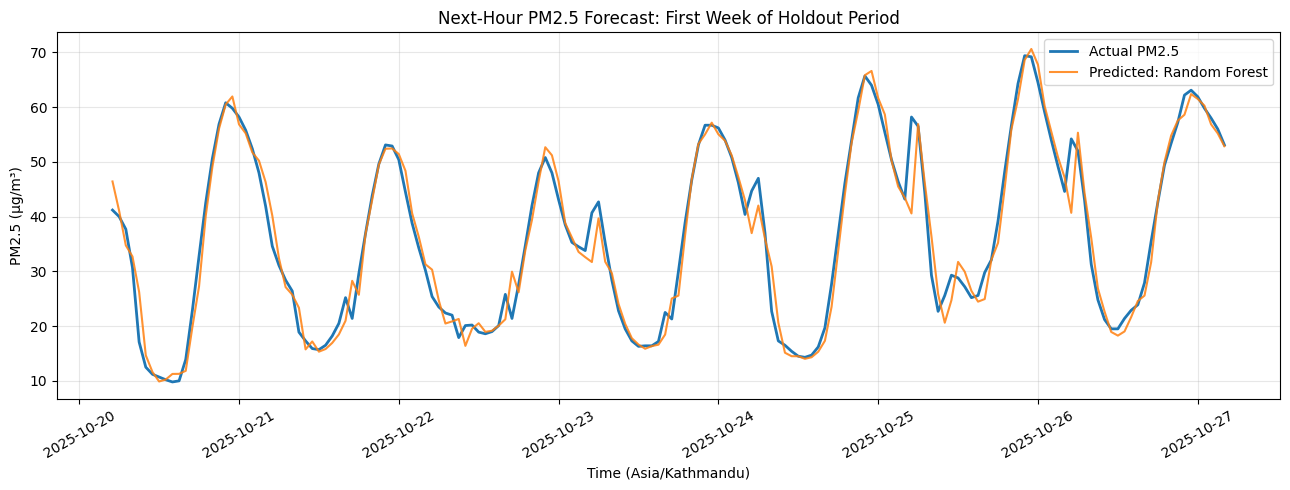

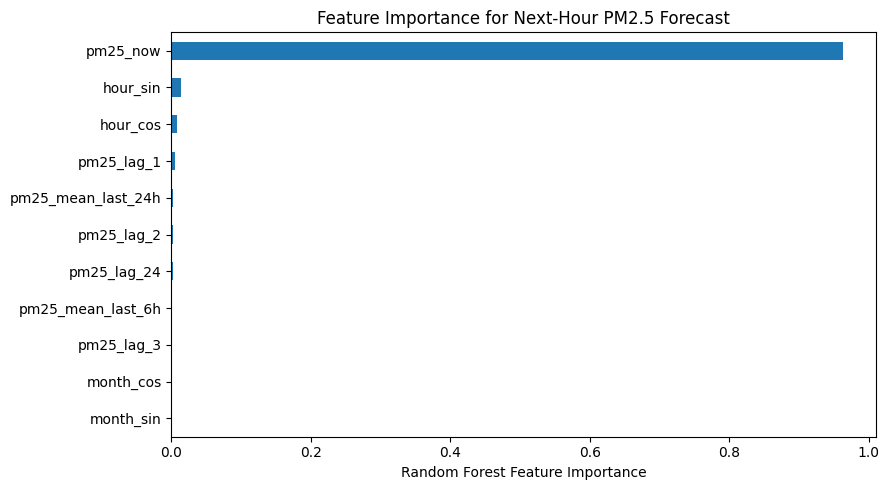

In [11]:
# Visual comparison: first 168 holdout hours (one week)
best_model = metrics_df.iloc[0]['Model']
n_plot = min(168, len(y_test))
plt.figure(figsize=(13, 5))
plt.plot(comparison['time'].iloc[:n_plot], comparison['actual_pm25'].iloc[:n_plot],
         label='Actual PM2.5', linewidth=2)
plt.plot(comparison['time'].iloc[:n_plot], predictions[best_model][:n_plot],
         label=f'Predicted: {best_model}', alpha=0.85)
plt.xlabel('Time (Asia/Kathmandu)')
plt.ylabel('PM2.5 (µg/m³)')
plt.title('Next-Hour PM2.5 Forecast: First Week of Holdout Period')
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig('Ratnanagar_PM25_Prediction_Comparison_2025.png', dpi=200)
plt.show()

importance = pd.Series(models['Random Forest'].feature_importances_, index=features).sort_values()
plt.figure(figsize=(9, 5))
importance.plot(kind='barh')
plt.xlabel('Random Forest Feature Importance')
plt.title('Feature Importance for Next-Hour PM2.5 Forecast')
plt.tight_layout()
plt.savefig('Ratnanagar_PM25_Feature_Importance_2025.png', dpi=200)
plt.show()


### 7.4 Interpretation and limitations

Interpret the **executed** model metrics above; no accuracy values are claimed in advance. The persistence baseline is essential because adjacent hourly PM2.5 values may be similar. The chronological holdout tests one future segment of 2025, not generalization across different years or locations. Air-quality values are modelled estimates; any forecast is a forecast of those estimates, not validated ground-level measurements. Additional years, meteorological predictors, independent monitoring observations, and rolling-origin validation would strengthen future research.


## 7. Results and Discussion

This project analyzed estimated hourly air-quality data for Ratnanagar, Chitwan, Nepal, from January to December 2025. The dataset contained 8,760 hourly observations.

### 7.1 Key Findings

1. **PM2.5 Concentration:** The estimated annual average PM2.5 concentration was approximately 48.75 µg/m³.

2. **Seasonal Variation:** PM2.5 concentrations were generally higher during winter and lower during the monsoon season.

3. **PM2.5 and PM10 Relationship:** A strong positive correlation (r = 0.89) was observed between PM2.5 and PM10 concentrations.

4. **Nitrogen Dioxide and Ozone:** A strong negative correlation (r = -0.82) was observed between nitrogen dioxide and ozone.

5. **AQI Classification:** Most estimated hourly AQI values fell into the Moderate, Unhealthy for Sensitive Groups, and Unhealthy categories.

### 7.2 Limitations

The dataset contains modelled air-quality estimates rather than direct measurements from a local monitoring station. Therefore, the results should be interpreted as estimated pollution patterns.

Additionally, correlations between pollutants do not necessarily indicate causal relationships.

## 8. Conclusion

The analysis identified seasonal variations in estimated air pollution levels in Ratnanagar, Nepal, during 2025.

Higher PM2.5 concentrations were observed during winter, while lower concentrations occurred during the monsoon period.

The project demonstrated practical applications of Python, Pandas, NumPy, Matplotlib, Seaborn, and exploratory data analysis techniques in environmental research.

Future studies could incorporate ground-based measurements and meteorological variables to improve the reliability of air-quality assessments.